# deps

In [ ]:
# get the version of the package use

import sys

import math

import matplotlib
import matplotlib.pyplot as pyplot
import pandas
import scipy

print("python     :", sys.version.split(' ')[0])
for module in (matplotlib, pandas, scipy):
    print(f"{module.__name__:<11}:", module.__version__)

: 

# Constant

In [ ]:
DATA_PATH = "../data"
CSV_CLEAN = "boardGamesClean.csv"

#column name
TITLE = "Title"

ORIGINAL_TYPE = "Type 1"
TYPE = "Type"

COMPLEXITY = "Complexity"

MEAN_TIME = "Mean time"

ORIGINAL_AVERAGE_RATING = "Avg rating"
AVERAGE_RATING = "Average rating"

ORIGINAL_NUMBER_VOTE = "Num of voters"
NUMBER_VOTE = "Number of voters"

POPULARITY = "Popularity"

# Loading data

In [ ]:
print(f"{DATA_PATH}/{CSV_CLEAN}")
cleanDataFrame = pandas.read_csv(f"{DATA_PATH}/{CSV_CLEAN}")
cleanDataFrame = cleanDataFrame.rename(columns={
    ORIGINAL_TYPE: TYPE,
    ORIGINAL_AVERAGE_RATING: AVERAGE_RATING,
    ORIGINAL_NUMBER_VOTE: NUMBER_VOTE
})

## Popularity

the popularity is calculate with

In [ ]:
# caclculate the popularity
popularity = [(r/10)*100 * math.log10(val + 1) for r, val in zip(cleanDataFrame[AVERAGE_RATING], cleanDataFrame[NUMBER_VOTE])]

#insert the new column
cleanDataFrame.insert(1, POPULARITY, popularity, allow_duplicates=True)

In [ ]:
# round all value to 2
cleanDataFrame = cleanDataFrame.round(2)

#sort
cleanDataFrame = cleanDataFrame.sort_values(by=POPULARITY, ascending=True).reset_index(drop=True)

# generic function

In [ ]:
#! function to show the evolution of a column by a graph

def evolutionGraph(rowName, dataFrame = cleanDataFrame, graphTitle=None, sort=True):
    if graphTitle is None:
        graphTitle = f"evolution of {rowName}"

    # take the values of the column sort it and add it to the graph
    if(sort) :
        pyplot.plot(dataFrame[rowName].sort_values(ascending=True).reset_index(drop=True), color="b", marker=".", linestyle="none")
    else :
        pyplot.plot(dataFrame[rowName], color="b", marker=".", linestyle="none")

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel("Game Index")
    # set the label of the y axe
    pyplot.ylabel(rowName)
    # add a grib to the graph
    pyplot.grid(True)

In [ ]:
#! function to show a graph of Y by X and allow adding a line to the graph

def yByXGraph(rowNameX, rowNameY, dataFrame = cleanDataFrame, graphTitle=None, sort=True, lineParams=None):
    # set the title if not already define
    if graphTitle is None:
        graphTitle = f"{rowNameY} by {rowNameX}"

    # drop all column that will not be use
    plotDf = dataFrame[[rowNameX, rowNameY]].dropna()
    # sort the value if it's ask
    if sort:
        plotDf = plotDf.sort_values(by=rowNameX, ascending=True)

    x = plotDf[rowNameX]
    y = plotDf[rowNameY]

    # add all value to the plot    
    pyplot.plot(x, y, color="b", marker=".", linestyle="none")

    # add the line if require
    if lineParams is not None and not plotDf.empty:
        # get b0 and b1
        b0, b1 = lineParams
        # get the min and max x value
        xMin = float(x.min())
        xMax = float(x.max())
        xPoints = [xMin, xMax]
        # calculate the y min and max value
        yPoints = [b0 + b1 * xMin, b0 + b1 * xMax]
        pyplot.plot(xPoints, yPoints, color="r", linestyle="--")

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel(rowNameX)
    # set the label of the y axe
    pyplot.ylabel(rowNameY)
    # add a grib to the graph
    pyplot.grid(True)

In [ ]:
#! function to make a boxplot of a column

def boxplot(rowName, dataFrame = cleanDataFrame, whis=(0, 100), graphTitle=None):
    # generate the title if is not provided
    if graphTitle is None:
        graphTitle = f"boxplot of {rowName}"

    #take the values of the column and make a boxplot
    pyplot.boxplot(dataFrame[rowName], whis=whis)

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel("Distribution")
    # set the label of the y axe
    pyplot.ylabel(rowName)
    # show the graph
    pyplot.grid(True)

    #  calculate all the quartile and the min/max value
    minVal = dataFrame[rowName].quantile(0)
    q1 = dataFrame[rowName].quantile(0.25)
    q2 = dataFrame[rowName].quantile(0.50)
    q3 = dataFrame[rowName].quantile(0.75)
    maxVal = dataFrame[rowName].quantile(1)
    iqr = q3 - q1;

    # create a string with all the stats
    statsText = (
        f"MAX: {maxVal:.2f}\n"
        f"Q3:  {q3:.2f}\n"
        f"Q2:  {q2:.2f}\n"
        f"Q1:  {q1:.2f}\n"
        f"MIN: {minVal:.2f}\n"
        f"IQR: {iqr:.2f}"
    )

    # display text on the graph
    pyplot.text(
        0.03, 0.05, statsText,
        # say to place the text relatively
        transform=pyplot.gca().transAxes,
        fontsize=9, 
        verticalalignment='bottom',
        horizontalalignment='left',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
    )

    

In [ ]:
#! function to make a bar graph

def barGraph(rowName, valueColumn=None, dataFrame = cleanDataFrame, agg_func='mean', color="skyblue", graphTitle=None, showText=False, onConsole=True):
    # generate the title if is not provided
    if graphTitle is None:
        if valueColumn is None:
            graphTitle = f"Number of {rowName}"
        else:
            graphTitle = f"{agg_func.capitalize()} of {valueColumn} by {rowName}"

    # process data depending on whether a value column is specified
    if valueColumn is None:
        dataPlot = dataFrame[rowName].value_counts().sort_values()
        yLabel = f"Number of {rowName}"
    else:
        dataPlot = dataFrame.groupby(rowName)[valueColumn].agg(agg_func).sort_values()
        yLabel = f"{agg_func.capitalize()} of {valueColumn}"

    # Create the plot
    dataPlot.plot(kind="bar", color=color)

    # set title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel(rowName)
    # set the label of the y axe
    pyplot.ylabel(yLabel)
    # rotate the x values name
    pyplot.xticks(rotation=45, ha="right")
    
    # format data stats
    formattedLines = []

    # travel all items to get it's key and it's value
    for key, value in dataPlot.items():
        
        # check if is a float or not
        if isinstance(value, float):
            # round to 2
            line = f"{key}: {value:.2f}"
        else:
            line = f"{key}: {value}"
            
        # add the line to the list
        formattedLines.append(line)

    # join each part of the list with \n
    statsText = "\n".join(formattedLines)

    # show the stat
    if(showText):
        pyplot.text(
            0.03, 0.95, statsText,
            fontsize=8, 
            # say to place the text relatively
            transform=pyplot.gca().transAxes,
            verticalalignment='top',
            horizontalalignment='left',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
        )

    pyplot.tight_layout() 

    if(onConsole):
        print(statsText)

# Get Global information

In [ ]:
print("rows, columns:", cleanDataFrame.shape)
cleanDataFrame.info()
# show all rows
cleanDataFrame.head(cleanDataFrame.shape[0])

In [ ]:
# count = number of row fill with a value
# mean = mean of all the value
cross_table = pandas.pivot_table(
    cleanDataFrame,
    values=[AVERAGE_RATING, NUMBER_VOTE],
    index=[TYPE],
    aggfunc={"mean", "count"},
).round(2)

print(cross_table)

## evolution graph

In [ ]:
#! graph show the evolution of the average rating

# set the size of the graph
pyplot.figure(figsize=(10, 5))
evolutionGraph(AVERAGE_RATING)
pyplot.show()

In [ ]:
#! graph show the evolution of the popularity

# set the size of the graph
pyplot.figure(figsize=(10, 5))
evolutionGraph(POPULARITY)
pyplot.show()

## boxplot

In [ ]:
# graph show the evolution of the average rating
pyplot.figure(figsize=(40, 20))

pyplot.subplot(3, 2, 1)

boxplot(AVERAGE_RATING, whis=1.5)

pyplot.subplot(3, 2, 2)

boxplot(AVERAGE_RATING)

pyplot.subplot(3, 2, 3)

boxplot(NUMBER_VOTE, whis=1.5)

pyplot.subplot(3, 2, 4)

boxplot(NUMBER_VOTE)

pyplot.subplot(3, 2, 5)

boxplot(POPULARITY, whis=1.5)
pyplot.subplot(3, 2, 6)

boxplot(POPULARITY)

pyplot.subplots_adjust(wspace=0.075, hspace=0.175)
pyplot.show()

## number of value out of the box

In [ ]:
# Liste des colonnes à analyser
columns_to_check = [AVERAGE_RATING, NUMBER_VOTE, POPULARITY]

for col in columns_to_check:
    # Calcul de Q1 (25e percentile) et Q3 (75e percentile)
    Q1 = cleanDataFrame[col].quantile(0.25)
    Q3 = cleanDataFrame[col].quantile(0.75)
    
    # Calcul de l'écart interquartile (IQR)
    IQR = Q3 - Q1
    
    # Seuils inférieur et supérieur
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Compter les valeurs en dessous et au-dessus des seuils
    count_lower_outliers = (cleanDataFrame[col] < lower_bound).sum()
    count_upper_outliers = (cleanDataFrame[col] > upper_bound).sum()
    
    print(f"--- {col} ---")
    print(f"  Valeurs < Q1 - 1.5*IQR (en dessous) : {count_lower_outliers} (Seuil : {lower_bound:.2f})")
    print(f"  Valeurs > Q3 + 1.5*IQR (au-dessus)  : {count_upper_outliers} (Seuil : {upper_bound:.2f})")

## bar graph

In [ ]:
#! show bar graph with the number of element for a type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, color="skyblue")
pyplot.show()

In [ ]:
#! show a bar graph with the mean time by type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, valueColumn=MEAN_TIME, agg_func='mean', color="salmon")
pyplot.show()

In [ ]:
#! mean of the rating by type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, valueColumn=AVERAGE_RATING, agg_func='mean', color="salmon")
pyplot.show()

# change dataset for deleting out of bound values

In [ ]:
#! remove out of bound value
def remove_outliers_iqr(df, columns):
    # Supprime les valeurs aberrantes (en dehors de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]) 
    # pour les colonnes spécifiées dans un DataFrame.

    cleanerDataFrame = df.copy()
    
    for col in columns:
        Q1 = cleanerDataFrame[col].quantile(0.25)
        Q3 = cleanerDataFrame[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Filtrer les lignes
        cleanerDataFrame = cleanerDataFrame[
            (cleanerDataFrame[col] >= lower_bound) & 
            (cleanerDataFrame[col] <= upper_bound)
        ]
        
    return cleanerDataFrame

def remove_outliers_iqr_iterative(df, columns):
    cleanerDataFrame = df.copy()
    clean = False
    
    while not(clean):
        # Sauvegarde de la taille actuelle pour comparer après un tour
        previous_shape = cleanerDataFrame.shape
        
        # Application du nettoyage IQR
        cleanerDataFrame = remove_outliers_iqr(cleanerDataFrame, columns)
        
        # Si la taille n'a pas changé, le processus a convergé
        clean = cleanerDataFrame.shape == previous_shape
            
    return cleanerDataFrame

In [ ]:
#! boxplot of rating, number of vote and popularity only with popular game

cleanerDataFrame = remove_outliers_iqr(cleanDataFrame, [AVERAGE_RATING, NUMBER_VOTE, POPULARITY])
cleanestDataFrame = remove_outliers_iqr_iterative(cleanDataFrame, [AVERAGE_RATING, NUMBER_VOTE, POPULARITY])

print(f"cleaner: {cleanerDataFrame.shape[0]} {round(cleanerDataFrame.shape[0]/cleanDataFrame.shape[0], 4)*100}%")
print(f"cleanest: {cleanestDataFrame.shape[0]} {round(cleanestDataFrame.shape[0]/cleanDataFrame.shape[0], 4)*100}%")

pyplot.figure(figsize=(40, 20))

pyplot.subplot(3, 2, 1)
boxplot(AVERAGE_RATING, whis=1.5, dataFrame=cleanerDataFrame)

pyplot.subplot(3, 2, 3)
boxplot(NUMBER_VOTE, whis=1.5, dataFrame=cleanerDataFrame)

pyplot.subplot(3, 2, 5)
boxplot(POPULARITY, whis=1.5, dataFrame=cleanerDataFrame)

pyplot.subplot(3, 2, 2)
boxplot(AVERAGE_RATING, whis=1.5, dataFrame=cleanestDataFrame)

pyplot.subplot(3, 2, 4)
boxplot(NUMBER_VOTE, whis=1.5, dataFrame=cleanestDataFrame)

pyplot.subplot(3, 2, 6)
boxplot(POPULARITY, whis=1.5, dataFrame=cleanestDataFrame)



pyplot.show()

# change dataset for popular only

In [ ]:
#! remove popular game
popularDataFrame = cleanestDataFrame[cleanestDataFrame[POPULARITY] > cleanestDataFrame[POPULARITY].quantile(0.75)]
print(f"{popularDataFrame.shape[0]}\n{round(popularDataFrame.shape[0]/cleanestDataFrame.shape[0], 4)*100}%")
print(f"{round(popularDataFrame.shape[0]/cleanDataFrame.shape[0], 4)*100}%")

In [ ]:
# pandas.set_option('display.max_rows', None)
# pandas.set_option('display.max_columns', None)

popularDataFrame.sort_values(by=POPULARITY, ascending=True).reset_index(drop=True).head(popularDataFrame.shape[0])

In [ ]:
#! boxplot of rating, number of vote and popularity only with popular game
pyplot.figure(figsize=(12.5, 20))

pyplot.subplot(3, 1, 1)
boxplot(AVERAGE_RATING, dataFrame=popularDataFrame)

pyplot.subplot(3, 1, 2)
boxplot(NUMBER_VOTE, dataFrame=popularDataFrame)

pyplot.subplot(3, 1, 3)
boxplot(POPULARITY, dataFrame=popularDataFrame)



pyplot.show()

In [ ]:
pyplot.figure(figsize=[15, 25])
pyplot.subplot(3, 2, 1)
evolutionGraph(POPULARITY, dataFrame=popularDataFrame, sort=False)
pyplot.subplot(3, 2, 3)
evolutionGraph(AVERAGE_RATING, dataFrame=popularDataFrame, sort=False)
pyplot.subplot(3, 2, 5)
evolutionGraph(NUMBER_VOTE, dataFrame=popularDataFrame, sort=False)

pyplot.subplot(3, 2, 2)
evolutionGraph(POPULARITY, dataFrame=cleanDataFrame, sort=False)
pyplot.subplot(3, 2, 4)
evolutionGraph(AVERAGE_RATING, dataFrame=cleanDataFrame, sort=False)
pyplot.subplot(3, 2, 6)
evolutionGraph(NUMBER_VOTE, dataFrame=cleanDataFrame, sort=False)
pyplot.show()

# hypothese

## seeing the two var use

In [25]:
pyplot.figure(figsize=[10, 5])
pyplot.subplot(1, 2, 1)
yByXGraph(POPULARITY, AVERAGE_RATING, popularDataFrame)
pyplot.subplot(1, 2, 2)
yByXGraph(AVERAGE_RATING, POPULARITY, popularDataFrame)
pyplot.show()

equation to check if there is a corelation between the two variable (popularity, average rating) :

y = B + B * X + E

H == B1 != 0 y a une corelation

H == B1  = 0 y a pas

In [ ]:
result = scipy.stats.linregress(popularDataFrame[POPULARITY], popularDataFrame[AVERAGE_RATING])
print(result)

: 

In [27]:
# 1. Extract parameters
B0 = result.intercept
B1 = result.slope

print("B0: ", B0)
print("B1: ", B1)

B0:  2.6185625800427053
B1:  0.021571089573832473


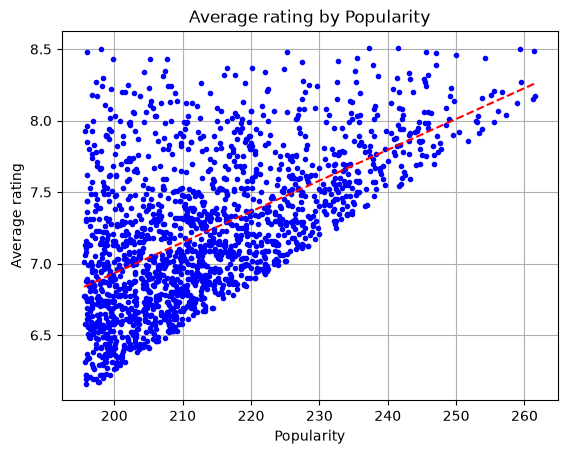

In [28]:
yByXGraph(POPULARITY, AVERAGE_RATING, dataFrame=popularDataFrame, lineParams=[B0, B1])
pyplot.show()

# choix gouvernance